# 03. Avaliação quantitativa do RAG

O enunciado é explícito: não basta a resposta ser bem escrita; vale a capacidade de
**recuperar informação relevante** e de **gerar respostas coerentes com as evidências**,
reconhecendo quando não há informação suficiente. Este notebook mede isso e mostra como as
medições **mudaram o sistema**: duas técnicas que pareciam boas no papel foram descartadas.

**Conjunto de avaliação** (`eval/perguntas.json`): 40 perguntas. 28 respondíveis (os cinco tipos
de exploração do enunciado + 8 com recorte por metadado), 6 fora do escopo (incluindo uma
tentativa de *prompt injection*) e 6 sem evidência na base (drone, cashback, criptomoeda...).
Cada pergunta respondível tem um **critério de relevância** escrito à mão.

**Protocolo de recuperação (pooling, como no TREC).** Cada configuração recupera para cada
pergunta; a união dos top-10 de todas, mais os contextos finais e uma amostra ao longo do ranking,
forma o *pool*; um **LLM-juiz diferente do gerador** dá relevância 0/1/2 a cada par (pergunta,
avaliação). Nas perguntas com recorte, o juiz vê os metadados de cada avaliação (categoria,
região, nota, entrega, mês): sem isso ele não teria como saber se uma avaliação é "de beleza e
saúde" ou "do Nordeste".

| Métrica | Definição |
|---|---|
| P@10 | fração do top-10 com relevância 2 (evidência clara) |
| nDCG@10 | ganho graduado (0/1/2) descontado pela posição, normalizado pelo ideal do pool |
| MRR | inverso da posição da primeira evidência clara |
| Hit@5 | há ao menos uma evidência clara no top-5? |
| Conformidade@10 | fração do top-10 que respeita o recorte pedido |

Tudo gerado por `uv run voc avaliar` (JSON em `reports/`).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from voc_rag.config import REPORTS_DIR, EVAL_DIR
from voc_rag import viz

viz.aplica_estilo()
rec = json.loads((REPORTS_DIR / "avaliacao_recuperacao.json").read_text(encoding="utf-8"))
ger = json.loads((REPORTS_DIR / "avaliacao_geracao.json").read_text(encoding="utf-8"))
julg = pd.read_csv(EVAL_DIR / "julgamentos_relevancia.csv")
cfg = pd.DataFrame(rec["configuracoes"]).T
print(f"{rec['n_julgamentos']} julgamentos de relevância | {rec['n_perguntas_respondiveis']} perguntas respondíveis")
print("Distribuição dos julgamentos:", julg["relevancia"].value_counts().sort_index().to_dict())
print("Julgamentos por modelo juiz:", julg["juiz"].value_counts().to_dict())

3251 julgamentos de relevância | 28 perguntas respondíveis
Distribuição dos julgamentos: {0: 820, 1: 327, 2: 2104}
Julgamentos por modelo juiz: {'gemini-3.1-flash-lite': 2742, 'gemini-3.8-flash': 292, 'gemini-3.7-flash': 217}


**Sobre o juiz.** No plano gratuito do Gemini, os modelos "flash" têm 20 requisições por dia;
quando esgotaram ou ficaram sobrecarregados, o julgamento passou ao juiz de reserva
(`gemini-3.1-flash-lite`). Isso **não distorce a comparação entre configurações**: todo o pool de
uma pergunta é julgado por um único modelo, então as configurações são comparadas com a mesma
régua dentro de cada pergunta. A concordância entre juízes está na seção 6.

## 1. Ablação: o caminho até o sistema final

In [2]:
caminho = ["A0_denso_pergunta_crua", "A1_reescrita", "V1_hibrido_so_reescrita",
           "F1_final_so_reescrita"]
nomes = ["RAG ingênuo (pergunta crua, só vetor)", "+ reescrita da pergunta",
         "+ BM25 (híbrido, RRF)", "+ metadados, polaridade e porteiro (final)"]
abl = cfg.loc[caminho, ["p@5", "p@10", "ndcg@10", "mrr", "hit@5"]].astype(float)
abl.index = nomes
abl.round(3)

,p@5,p@10,ndcg@10,mrr,hit@5
"RAG ingênuo (pergunta crua, só vetor)",0.600,0.607,0.664,0.722,0.893
+ reescrita da pergunta,0.821,0.800,0.817,0.863,0.893
"+ BM25 (híbrido, RRF)",0.786,0.804,0.812,0.869,0.893
"+ metadados, polaridade e porteiro (final)",0.914,0.939,0.943,0.964,1.000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


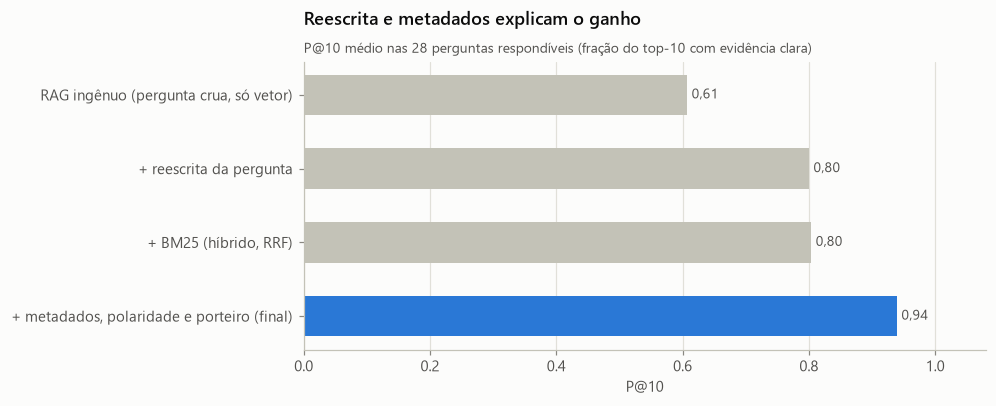

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(abl))[::-1]
cores = [viz.EIXO] * (len(abl) - 1) + [viz.SERIE]
barras = ax.barh(y, abl["p@10"], height=0.55, color=cores)
viz.rotula_barras(ax, barras, "{:.2f}", horizontal=True)
ax.set_yticks(y, abl.index); ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False)
ax.set_title("Reescrita e metadados explicam o ganho")
viz.subtitulo(ax, "P@10 médio nas 28 perguntas respondíveis (fração do top-10 com evidência clara)")
ax.set_xlabel("P@10")
viz.salva(fig, "avaliacao_ablacao"); fig

**Leitura.** A **reescrita da pergunta** é o maior salto isolado: a pergunta do gestor está em
registro analítico, o comentário em registro coloquial, e a busca vetorial com a pergunta crua
traz textos que se parecem com perguntas, não com relatos. O **BM25** é neutro aqui (ele ajuda
quando há várias consultas, seção 2). Os **metadados** levam o sistema ao patamar final porque
as perguntas com recorte deixam de ser respondidas com avaliações fora do recorte.

## 2. O que foi testado e descartado

In [4]:
testes = pd.DataFrame([
    ("multi-query + HyDE", "A2_multiquery_hyde", "A1_reescrita"),
    ("+ BM25 quando há várias consultas", "A3_hibrido_bm25_rrf", "A2_multiquery_hyde"),
    ("reranker ordenando (máximo entre consultas)", "A4_reranker", "A3_hibrido_bm25_rrf"),
    ("reranker contra a consulta principal", "V3_reranker_consulta_principal", "A3_hibrido_bm25_rrf"),
    ("reranker pela média das consultas", "V4_reranker_media", "A3_hibrido_bm25_rrf"),
    ("sistema completo ordenado pelo reranker", "A5_metadados_polaridade", "F1_final_so_reescrita"),
], columns=["técnica", "com", "sem"])
testes["P@10 com"] = [float(cfg.loc[c, "p@10"]) for c in testes["com"]]
testes["P@10 sem"] = [float(cfg.loc[s, "p@10"]) for s in testes["sem"]]
testes["diferença"] = testes["P@10 com"] - testes["P@10 sem"]
testes[["técnica", "P@10 com", "P@10 sem", "diferença"]].round(3)

,técnica,P@10 com,P@10 sem,diferença
0,multi-query + HyDE,0.750,0.800,-0.050
1,+ BM25 quando há várias consultas,0.775,0.750,0.025
2,reranker ordenando (máximo entre consultas),0.707,0.775,-0.068
3,reranker contra a consulta principal,0.757,0.775,-0.018
4,reranker pela média das consultas,0.661,0.775,-0.114
5,sistema completo ordenado pelo reranker,0.857,0.939,-0.082


In [5]:
pq = pd.DataFrame({q: {k: v["p@10"] for k, v in d.items()} for q, d in rec["por_pergunta"].items()}).T
cols = ["A3_hibrido_bm25_rrf", "A4_reranker", "V3_reranker_consulta_principal"]
dif = pq[cols].assign(delta=pq["A4_reranker"] - pq["A3_hibrido_bm25_rrf"])
dif[dif["delta"] != 0].sort_values("delta").round(2)

,A3_hibrido_bm25_rrf,A4_reranker,V3_reranker_consulta_principal,delta
Q21,0.9,0.5,0.8,-0.4
Q20,0.7,0.3,0.4,-0.4
Q23,0.5,0.2,0.4,-0.3
Q10,0.7,0.4,0.5,-0.3
Q22,0.2,0.0,0.5,-0.2
Q25,0.1,0.0,0.2,-0.1
Q27,0.1,0.0,0.2,-0.1
Q28,0.1,0.0,0.0,-0.1
Q11,1.0,0.9,0.9,-0.1
Q24,0.3,0.2,0.3,-0.1


**Leitura.** Multi-query e HyDE pioram a média: mesmo com a regra de fidelidade no prompt, as
variações puxam temas vizinhos. O reranker cross-encoder piora em **todas** as variantes de
ordenação. A tabela pergunta a pergunta mostra onde: embalagem (Q20), qualidade de móveis (Q28),
elogios ao atendimento (Q10). O cross-encoder trata "produto veio quebrado" como relevante para
"embalagem" e "qualidade", e põe essas avaliações no topo com escore 1,00. A decisão (D12): a
ordem final é a da fusão RRF, e o reranker fica só como **porteiro** (seção 5).

## 3. Escolha do modelo de embedding

Mesma configuração para os três (consulta reescrita, só busca vetorial, sem reranker), para
isolar a qualidade do embedding.

In [6]:
emb = cfg.loc[["E_minilm", "E_e5_base", "E_bge_m3"], ["p@10", "ndcg@10", "mrr", "hit@5"]].astype(float)
emb.index = ["paraphrase-multilingual-MiniLM-L12-v2 (118M, 384d)",
             "multilingual-e5-base (278M, 768d)", "bge-m3 (568M, 1024d)"]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
y = np.arange(len(emb))[::-1]
barras = ax.barh(y, emb["ndcg@10"], height=0.5, color=[viz.EIXO, viz.EIXO, viz.SERIE])
viz.rotula_barras(ax, barras, "{:.2f}", horizontal=True)
ax.set_yticks(y, emb.index); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_title("bge-m3 recupera melhor as avaliações em português")
viz.subtitulo(ax, "nDCG@10, consulta reescrita, só busca vetorial")
viz.salva(fig, "avaliacao_embeddings")
emb.round(3)

,p@10,ndcg@10,mrr,hit@5
"paraphrase-multilingual-MiniLM-L12-v2 (118M, 384d)",0.704,0.713,0.739,0.929
"multilingual-e5-base (278M, 768d)",0.711,0.735,0.796,0.857
"bge-m3 (568M, 1024d)",0.800,0.817,0.863,0.893


## 4. Metadados: o ganho do desafio adicional

Mesma configuração com e sem filtros (V1 x sistema final) nas 8 perguntas com recorte explícito.

In [7]:
sem, com = "V1_hibrido_so_reescrita", "F1_final_so_reescrita"
meta = pd.DataFrame({
    "sem filtros": [cfg.loc[sem, "metadados_conformidade@10"], cfg.loc[sem, "metadados_p@10"]],
    "com filtros": [cfg.loc[com, "metadados_conformidade@10"], cfg.loc[com, "metadados_p@10"]],
}, index=["conformidade ao recorte @10", "P@10"]).astype(float)
pp = pd.DataFrame({q: {k: v.get("conformidade_metadado@10") for k, v in d.items()}
                   for q, d in rec["por_pergunta"].items()}).T.dropna(how="all")
display(meta.round(3))
pp[[sem, com]].rename(columns={sem: "sem filtros", com: "com filtros"}).dropna().round(2)

,sem filtros,com filtros
conformidade ao recorte @10,0.425,0.912
P@10,0.388,0.850


,sem filtros,com filtros
Q21,0.9,1.0
Q22,0.6,1.0
Q23,0.7,1.0
Q24,0.1,1.0
Q25,0.3,1.0
Q26,0.7,1.0
Q27,0.1,0.5
Q28,0.0,0.8


**Leitura.** Sem filtro, a busca acha o **tema** certo fora do **recorte** (uma reclamação de
móveis numa pergunta sobre cama, mesa e banho; uma nota 4 numa pergunta sobre nota 1). Com o
filtro dentro da consulta ao banco vetorial, a conformidade passa de cerca de 40% para mais de
90%. Não chega a 100% porque o filtro aplicado é o que a análise da pergunta extraiu, e a
extração erra em alguns casos (seção 7).

## 5. O reranker como porteiro: calibração do limiar

AUC do escore do reranker contra o juiz: 0.7272


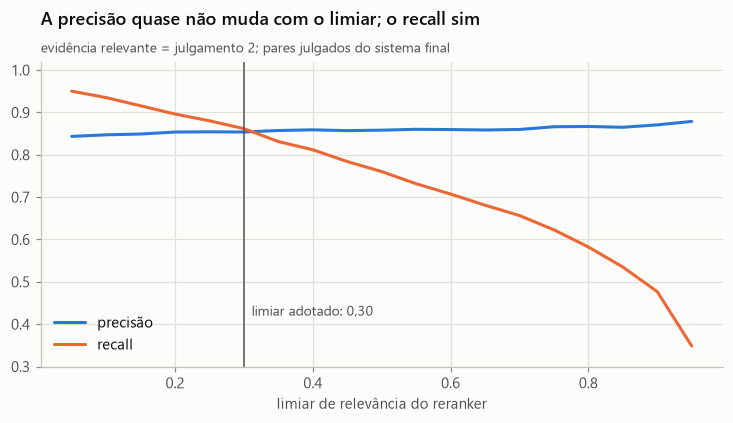

In [8]:
cal = rec["calibracao_limiar"]
tab = pd.DataFrame(cal["tabela"])
pares = pd.read_csv(REPORTS_DIR / "calibracao_pares.csv")
print(f"AUC do escore do reranker contra o juiz: {cal['auc_reranker_vs_juiz']}")
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, cor, nome in [("precisao", viz.CATEGORICAS[0], "precisão"),
                       ("recall", viz.CATEGORICAS[1], "recall")]:
    ax.plot(tab["limiar"], tab[col], color=cor, label=nome)
ax.axvline(0.30, color=viz.TINTA_2, linewidth=1)
ax.annotate("limiar adotado: 0,30", (0.30, 0.42), xytext=(5, 0), textcoords="offset points",
            color=viz.TINTA_2, fontsize=9)
ax.set_ylim(0.3, 1.02); ax.set_xlabel("limiar de relevância do reranker")
ax.set_title("A precisão quase não muda com o limiar; o recall sim")
viz.subtitulo(ax, "evidência relevante = julgamento 2; pares julgados do sistema final")
ax.legend(loc="lower left")
viz.salva(fig, "avaliacao_limiar"); fig

In [9]:
maximos = pares.groupby(["esperado", "qid"])["relevancia_reranker"].max().reset_index()
linhas = []
for t in (0.1, 0.2, 0.3, 0.4, 0.5):
    n = pares[pares["relevancia_reranker"] >= t].groupby("qid").size()
    sem_ev = maximos[maximos["esperado"] == "abster"]["qid"]
    resp = maximos[maximos["esperado"] == "responder"]["qid"]
    linhas.append({"limiar": t,
                   "sem evidência barradas (<3 relevantes)": f"{sum(n.get(q, 0) < 3 for q in sem_ev)} de {len(sem_ev)}",
                   "respondíveis barradas indevidamente": f"{sum(n.get(q, 0) < 3 for q in resp)} de {len(resp)}"})
pd.DataFrame(linhas)

,limiar,sem evidência barradas (<3 relevantes),respondíveis barradas indevidamente
0,0.1,3 de 5,0 de 28
1,0.2,3 de 5,0 de 28
2,0.3,3 de 5,0 de 28
3,0.4,3 de 5,0 de 28
4,0.5,3 de 5,0 de 28


**Leitura.** A precisão das evidências fica entre 0,84 e 0,88 em qualquer limiar, então o limiar
não serve para filtrar evidência. Serve para outra coisa: identificar perguntas sem evidência. Em
toda a faixa de 0,1 a 0,5 ele barra 3 das perguntas sem evidência já na recuperação e nenhuma
respondível. Adotamos 0,30, o meio da faixa (D13). As que passam (drone, cashback: avaliações sobre
"entrega" e "dinheiro de volta" pontuam alto) são barradas na geração.

## 6. Concordância entre juízes

Uma amostra de 6 perguntas foi rejulgada por um segundo modelo, `gemini-3.5-flash`, sem acesso
aos julgamentos originais. Kappa de Cohen acima de 0,8 é a faixa de concordância quase perfeita
(Landis e Koch, 1977).

In [10]:
conc = json.loads((REPORTS_DIR / "concordancia_juizes.json").read_text(encoding="utf-8"))
print(f"Pares rejulgados: {conc['pares']} em {conc['perguntas']}")
print(f"Juízes originais: {conc['juizes_originais']} | segundo juiz: {conc['segundo_juiz']}")
print(f"Concordância exata (0/1/2): {conc['concordancia_exata']:.1%} | kappa ponderado: {conc['kappa_ponderado']:.3f}")
print(f"Concordância em 'evidência clara': {conc['concordancia_binaria_relevante']:.1%} | kappa: {conc['kappa_binario_relevante']:.3f}")
pd.DataFrame(conc["matriz"]).rename_axis(index="original", columns="segundo juiz")

Pares rejulgados: 626 em ['Q04', 'Q10', 'Q13', 'Q20', 'Q22', 'Q28']
Juízes originais: {'gemini-3.1-flash-lite': 559, 'gemini-3.8-flash': 67} | segundo juiz: gemini-3.5-flash
Concordância exata (0/1/2): 90.4% | kappa ponderado: 0.887
Concordância em 'evidência clara': 96.0% | kappa: 0.916


segundo juiz,0,1,2
original,,,
0,145,16,0
1,19,50,12
2,1,12,371


## 7. Ponta a ponta: abstenção, citações, fidelidade e filtros

In [11]:
ab = ger["abstencao"]
print(f"Decisão responder x abster correta: {ab['acuracia']:.1%}")
print(f"Precisão da abstenção: {ab['precisao_abstencao']:.1%} | recall: {ab['recall_abstencao']:.1%}")
pd.DataFrame(ab["status_por_grupo"]).fillna(0).astype(int).T

Decisão responder x abster correta: 100.0%
Precisão da abstenção: 100.0% | recall: 100.0%


,respondida,fora_escopo,nao_respondida,sem_evidencia,evidencia_insuficiente
atendimento,2,0,0,0,0
elogios,3,0,0,0,0
entrega,4,0,0,0,0
evidencia,2,0,0,0,0
fora_escopo,0,6,0,0,0
insatisfacao,2,0,0,0,0
metadados,8,0,0,0,0
qualidade,4,0,0,0,0
reclamacoes,3,0,0,0,0
sem_evidencia,0,1,2,2,1


In [12]:
c, f = ger["citacoes"], ger["fidelidade"]
print(f"Citações verificadas: {c['citacoes_total']} | válidas: {c['citacoes_validas_pct']:.1%}")
print(f"Insights gerados: {c['insights_total']} | descartados por falta de evidência: "
      f"{c['insights_descartados_sem_evidencia']}")
print(f"Insights auditados: {f['insights_julgados']} | distribuição: {f['distribuicao']}")
print(f"Escore de fidelidade (sustentado = 1, parcial = 0,5): {f['escore_fidelidade']}")
print(f"Resumos integralmente sustentados: {f['resumos_sustentados_pct']}")
print(f"Precisão do contexto enviado ao LLM: {rec['precisao_contexto_final']:.1%}")

Citações verificadas: 635 | válidas: 100.0%
Insights gerados: 84 | descartados por falta de evidência: 0
Insights auditados: 84 | distribuição: {'sustentado': 78, 'parcial': 6}
Escore de fidelidade (sustentado = 1, parcial = 0,5): 0.9643
Resumos integralmente sustentados: 0.9643
Precisão do contexto enviado ao LLM: 91.0%


In [13]:
fe = ger["extracao_filtros"]
print(f"Extração de filtros correta em {fe['acerto_pct']:.0%} das {fe['perguntas']} perguntas com recorte")
pd.DataFrame(fe["por_pergunta"])

Extração de filtros correta em 100% das 8 perguntas com recorte


,id,acerto
0,Q21,True
1,Q22,True
2,Q23,True
3,Q24,True
4,Q25,True
5,Q26,True
6,Q27,True
7,Q28,True


In [14]:
pd.Series(ger["latencia"])

total_mediana_s_respondidas    0.310
recuperacao_mediana_s          0.293
geracao_mediana_s              0.000
analise_mediana_s              0.000
dtype: float64

## Conclusões

* **A reescrita da pergunta** é o componente mais valioso: aproxima o registro analítico do
  gestor do registro coloquial do cliente.
* **Medir mudou o sistema.** Multi-query, HyDE e a reordenação pelo reranker pioraram a
  recuperação neste domínio e saíram do caminho final; o reranker ganhou outro papel (porteiro),
  onde ajuda.
* **bge-m3** foi escolhido por medição entre três modelos.
* **Metadados** levam a conformidade ao recorte de cerca de 40% para mais de 90% e mais que dobram
  a precisão nas perguntas contextualizadas.
* A **abstenção** em três camadas é avaliada pergunta a pergunta, e cada citação é verificada por
  código; a fidelidade dos insights é auditada por um modelo diferente do gerador.